# Lab 2 (Parcial 2) · Parte II — Predicción del siguiente carácter con una RNN *vanilla*

## Objetivo

Entrenar una RNN simple (*vanilla*) que, tras leer **20 caracteres** de *The Time Machine* (H. G. Wells), prediga **el carácter siguiente**. Es un problema de clasificación con tantas clases como caracteres hay en el vocabulario; la métrica principal es la **exactitud** (*accuracy*) de esa predicción y, en el ejercicio 4, la **perplejidad**.

**Restricciones del enunciado** (no se pueden cambiar):

* Entradas codificadas en **one-hot** (no se permiten *embeddings* externos).
* Longitud máxima de secuencia: **20 caracteres**.
* Partición del texto **en orden**: el 30 % inicial para entrenamiento, el 10 % siguiente para validación y el 60 % restante para prueba.
* Arquitectura RNN estándar (*vanilla*): ni LSTM ni GRU.

Tareas de la guía (Parte II):

1. Analizar, ejecutar y comprender el código proporcionado (`Lab2_RNN_Next_Character.ipynb`): codificación de la entrada, funcionamiento de la RNN y cómo se predice el siguiente carácter.
2. Proponer e implementar **mejoras** (tasa de aprendizaje, optimizador, activación, inicialización, sobreajuste, gradientes que se desvanecen o explotan…), justificarlas y compararlas con la implementación original.
3. Con la mejor configuración, **20 ejecuciones independientes**: curva de aprendizaje media ± desviación típica y exactitud final en test (media ± desviación típica).
4. Calcular la **perplejidad** en test de la configuración optimizada.
5. **Conclusiones**: qué factores influyen más en el rendimiento.

## 0. Preparación del entorno

Se usa la CPU (el modelo es pequeño; en un Apple M3 una época tarda entre 1 y 5 segundos según el tamaño). El texto es el mismo `timemachine.txt` del Lab 1 (se copia en `data/`; si no está, se descarga del servidor de d2l, igual que en el Lab 1).

In [1]:
%matplotlib inline
import collections
import copy
import json
import math
import os
import re
import tempfile
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

LAB_DIR = None
for candidato in (Path.cwd(), Path.cwd() / 'Lab-2',
                  Path.cwd() / 'Parcial-2' / 'Lab-2-Recurrent-Neural-Networks' / 'Lab-2'):
    if (candidato / 'names.zip').exists() or (candidato / 'data').exists():
        LAB_DIR = candidato
        break
if LAB_DIR is None:
    raise FileNotFoundError('No se encuentra la carpeta del Lab 2 (con names.zip o data/)')

RUTA_TEXTO = LAB_DIR / 'data' / 'timemachine.txt'
if not RUTA_TEXTO.exists():
    RUTA_TEXTO.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve('http://d2l-data.s3-accelerate.amazonaws.com/timemachine.txt', RUTA_TEXTO)

torch.set_num_threads(min(4, os.cpu_count()))
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.precision', 4)
print('PyTorch', torch.__version__, '| texto:', RUTA_TEXTO.name, RUTA_TEXTO.stat().st_size, 'bytes')

PyTorch 2.15.0 | texto: timemachine.txt 178979 bytes


# 1. El código base, explicado y ejecutado

El código proporcionado es una única celda. Aquí se divide en bloques con comentarios; el único cambio es la ruta del archivo (y que los modelos intermedios se guardan en una carpeta temporal en lugar de en el directorio de trabajo).

## 1.1. Preprocesado y partición

Se pasa el texto a minúsculas y se conservan las 26 letras y el espacio. **Todo lo demás** (signos de puntuación, dígitos, saltos de línea) se sustituye por el token `'<unk>'`.

In [2]:
file_path = RUTA_TEXTO
with open(file_path, 'r', encoding='utf-8') as f:
    raw_text = f.read()
full_text = raw_text.lower()

# Preprocesado: minúsculas, 26 letras + espacio + unk
allowed_chars_set = set('abcdefghijklmnopqrstuvwxyz ')
unk_token = '<unk>'

cleaned_full_text = []
for char in full_text:
    if char in allowed_chars_set:
        cleaned_full_text.append(char)
    else:
        cleaned_full_text.append(unk_token)
full_text = "".join(cleaned_full_text)

# Partición 30 % / 10 % / 60 % EN ORDEN (no se puede modificar)
total_length = len(full_text)
train_split_idx = int(0.3 * total_length)
val_split_idx = int(0.1 * total_length) + train_split_idx
train_text = full_text[:train_split_idx]
val_text = full_text[train_split_idx:val_split_idx]
test_text = full_text[val_split_idx:]
print(f"Total text length: {total_length}  (el archivo original tiene {len(raw_text)} caracteres)")
print(f"Train text length: {len(train_text)}")
print(f"Validation text length: {len(val_text)}")
print(f"Test text length: {len(test_text)}")

# Vocabulario (después de limpiar)
chars = sorted(list(set(full_text)))
vocab_size = len(chars)
char2idx = {ch: i for i, ch in enumerate(chars)}
idx2char = {i: ch for i, ch in enumerate(chars)}
print('vocabulario:', vocab_size, chars)

Total text length: 214451  (el archivo original tiene 178979 caracteres)
Train text length: 64335
Validation text length: 21445
Test text length: 128671
vocabulario: 29 [' ', '<', '>', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


**Primer problema (un error).** `"".join(...)` pega la cadena `'<unk>'` **como cinco caracteres** sueltos: `<`, `u`, `n`, `k`, `>`. Por eso el texto «crece» de 178 979 a 214 451 caracteres y el vocabulario tiene 29 símbolos (las 26 letras, el espacio, `<` y `>`) en lugar de 28. Además, la red tiene que «predecir» los caracteres de dentro de `<unk>`, y eso es **trivial**: tras `<` siempre viene `u`, tras `<u` siempre `n`… Esos aciertos regalados inflan la exactitud y no tienen nada que ver con el idioma.

In [3]:
n_unk = full_text.count(unk_token)
print(f"'<unk>' aparece {n_unk} veces -> {4 * n_unk} caracteres ({4 * n_unk / len(full_text):.1%} del texto) "
      f"son las letras u, n, k, > dentro de '<unk>', totalmente predecibles")
print(repr(full_text[:120]))

'<unk>' aparece 8868 veces -> 35472 caracteres (16.5% del texto) son las letras u, n, k, > dentro de '<unk>', totalmente predecibles
'the time machine<unk> by h<unk> g<unk> wells <unk><unk><unk><unk><unk><unk><unk><unk><unk><unk><unk>i<unk><unk><unk>the '


## 1.2. Hiperparámetros y secuencias

Cada ejemplo es una ventana de 20 caracteres consecutivos (`seq_length`) y su objetivo es el carácter siguiente (`future_steps = 1`). Las ventanas se solapan: se desplazan de un carácter en un carácter. Cada carácter se guarda como su **índice** en el vocabulario.

In [4]:
# Hiperparámetros que NO se pueden modificar
seq_length = 20
future_steps = 1
# Hiperparámetros que se pueden modificar (valores por defecto)
batch_size = 32
num_epochs = 10
learning_rate = 0.01
patience = 10
hidden_sizes = [2, 4, 8, 16, 32, 64]
clip_value = 1.0
dropout_rate = 0.5

device = torch.device("cpu")

def create_sequences(text, seq_length, future_steps):
    X, Y = [], []
    for i in range(len(text) - seq_length - future_steps):
        seq = text[i:i + seq_length]
        target = text[i + seq_length:i + seq_length + future_steps]
        X.append([char2idx[ch] for ch in seq])
        Y.append([char2idx[ch] for ch in target])
    return np.array(X), np.array(Y)

X_train_seq, Y_train_seq = create_sequences(train_text, seq_length, future_steps)
X_val_seq, Y_val_seq = create_sequences(val_text, seq_length, future_steps)
X_test_seq, Y_test_seq = create_sequences(test_text, seq_length, future_steps)

X_train = torch.tensor(X_train_seq, dtype=torch.long).to(device)
Y_train = torch.tensor(Y_train_seq, dtype=torch.long).to(device)
X_val = torch.tensor(X_val_seq, dtype=torch.long).to(device)
Y_val = torch.tensor(Y_val_seq, dtype=torch.long).to(device)
X_test_final = torch.tensor(X_test_seq, dtype=torch.long).to(device)
Y_test_final = torch.tensor(Y_test_seq, dtype=torch.long).to(device)
print('X_train', tuple(X_train.shape), 'Y_train', tuple(Y_train.shape))
print('ejemplo:', repr(''.join(idx2char[int(i)] for i in X_train[100])), '->', repr(idx2char[int(Y_train[100, 0])]))

X_train (64314, 20) Y_train (64314, 1)
ejemplo: 'i<unk><unk><unk>the ' -> 't'


## 1.3. El modelo

`VanillaRNN` encadena:

1. **`nn.Embedding(vocab_size, vocab_size)`**: convierte cada índice en un vector de 29 números **aprendidos**. ⚠️ Esto **no es one-hot**: es una tabla de vectores entrenable, justo lo que la guía prohíbe («no estando permitido el uso de embeddings»). Con one-hot, el vector de cada carácter es fijo (un 1 en su posición).
2. **`nn.RNN(29, h, nonlinearity='relu')`**: la capa recurrente, $\mathbf{H}_t = \phi(\mathbf{X}_t\mathbf{W}_{xh} + \mathbf{H}_{t-1}\mathbf{W}_{hh} + \mathbf{b}_h)$ con $\phi=$ **ReLU** (no la tanh estándar). `batch_first=True` significa que el tensor es `(lote, tiempo, rasgos)`.
3. Se toma la salida del **último paso** (`out[:, -1, :]`, el estado tras leer los 20 caracteres), se aplica **dropout** (0,5) y una capa lineal $\mathbf{O} = \mathbf{H}_{20}\mathbf{W}_{hq} + \mathbf{b}_q$ que da una puntuación (*logit*) por carácter del vocabulario.
4. Pesos con **inicialización de Xavier** y sesgos a cero.

**Cómo se predice el siguiente carácter**: `CrossEntropyLoss` aplica internamente el **softmax** a los logits y mide $-\log p(\text{carácter correcto})$. En evaluación, la predicción es el carácter con logit máximo (`argmax`), que es también el de mayor probabilidad tras el softmax (el softmax no cambia el orden).

In [5]:
class VanillaRNN(nn.Module):
    def __init__(self, vocab_size, hidden_size, future_steps, dropout_rate=0.0):
        super(VanillaRNN, self).__init__()
        self.hidden_size = hidden_size
        self.future_steps = future_steps
        self.embedding = nn.Embedding(vocab_size, vocab_size)        # ⚠️ tabla aprendida, no one-hot
        self.rnn = nn.RNN(vocab_size, hidden_size, batch_first=True, nonlinearity='relu')
        self.dropout = nn.Dropout(dropout_rate)
        self.fc = nn.Linear(hidden_size, future_steps * vocab_size)
        self.init_weights()

    def init_weights(self):
        for name, param in self.rnn.named_parameters():
            if 'weight' in name:
                nn.init.xavier_uniform_(param)
            elif 'bias' in name:
                nn.init.zeros_(param)
        nn.init.xavier_uniform_(self.fc.weight)
        nn.init.zeros_(self.fc.bias)

    def forward(self, x):
        x = self.embedding(x)        # (B, 20) índices -> (B, 20, 29)
        out, _ = self.rnn(x)         # (B, 20, h): estado oculto en cada paso
        out = out[:, -1, :]          # solo el último paso
        out = self.dropout(out)
        out = self.fc(out)           # (B, 29) logits
        out = out.view(-1, self.future_steps, vocab_size)
        return out

## 1.4. Entrenamiento original

Para cada tamaño de capa oculta: Adam (tasa 0,01), recorte de gradiente a norma 1, y **parada temprana** con la pérdida de validación (se guarda el mejor modelo). Al final se mide la exactitud en test.

**Segundo problema (el más grave).** Cada «época» hace **una sola actualización de pesos** con *todo* el conjunto de entrenamiento a la vez (`rnn(X_train)`): `batch_size = 32` se define pero no se usa. Con 10 épocas, la red recibe **10 pasos de gradiente** en total; está prácticamente sin entrenar. Además `patience = 10` con `num_epochs = 10`: la parada temprana **nunca** se puede activar.


Training RNN with hidden size: 2


Hidden size 2, Final Test accuracy: 10.02%

Training RNN with hidden size: 4


Hidden size 4, Final Test accuracy: 20.40%

Training RNN with hidden size: 8


Hidden size 8, Final Test accuracy: 11.82%

Training RNN with hidden size: 16


Hidden size 16, Final Test accuracy: 23.99%

Training RNN with hidden size: 32


Hidden size 32, Final Test accuracy: 32.77%

Training RNN with hidden size: 64


Hidden size 64, Final Test accuracy: 37.73%

tiempo total: 13.1 s


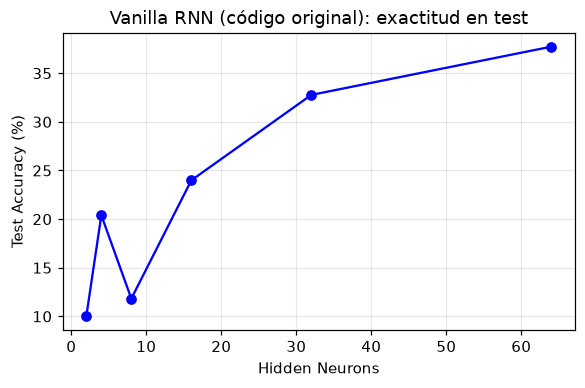

In [6]:
torch.manual_seed(0)
dir_modelos = tempfile.mkdtemp()
test_accuracies = []
inicio = time.time()

for hidden_size in hidden_sizes:
    print(f"\nTraining RNN with hidden size: {hidden_size}")
    rnn = VanillaRNN(vocab_size, hidden_size, future_steps, dropout_rate=dropout_rate).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(rnn.parameters(), lr=learning_rate)
    best_val_loss = float('inf')
    patience_counter = 0

    for epoch in range(num_epochs):
        rnn.train()
        optimizer.zero_grad()
        output = rnn(X_train)                      # ¡todo el conjunto de entrenamiento en un único paso!
        loss = sum(criterion(output[:, t, :], Y_train[:, t]) for t in range(future_steps))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(rnn.parameters(), clip_value)
        optimizer.step()

        rnn.eval()
        with torch.no_grad():
            val_output = rnn(X_val)
            val_loss = sum(criterion(val_output[:, t, :], Y_val[:, t]) for t in range(future_steps))

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            torch.save(rnn.state_dict(), f"{dir_modelos}/best_rnn_TimeMachine_{hidden_size}.pth")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch + 1}")
                break

    rnn.load_state_dict(torch.load(f"{dir_modelos}/best_rnn_TimeMachine_{hidden_size}.pth"))
    rnn.eval()
    with torch.no_grad():
        output = rnn(X_test_final)
        preds = output.argmax(dim=2)
        acc = (preds == Y_test_final).float().mean().item()
        test_accuracies.append(acc)
        print(f"Hidden size {hidden_size}, Final Test accuracy: {acc * 100:.2f}%")

t_original = time.time() - inicio
print(f'\ntiempo total: {t_original:.1f} s')
plt.figure(figsize=(6, 3.5))
plt.plot(hidden_sizes, [a * 100 for a in test_accuracies], marker='o', color='blue')
plt.xlabel("Hidden Neurons"); plt.ylabel("Test Accuracy (%)")
plt.title("Vanilla RNN (código original): exactitud en test"); plt.show()

In [7]:
frec_test = collections.Counter(test_text)
mas_comun, n_comun = frec_test.most_common(1)[0]
print(f"Referencia trivial: predecir siempre {mas_comun!r} acierta el {n_comun / len(test_text):.1%} del test")

Referencia trivial: predecir siempre ' ' acierta el 14.1% del test


**Qué sale del código original.** La exactitud en test crece con el tamaño oculto, hasta el **37,7 % con 64 neuronas**, pero está muy por debajo de lo que puede hacer una RNN y, además, **inflada**:

* El 16,5 % de los caracteres del texto son la «u», la «n», la «k» o el «>» de dentro de `<unk>`, que se predicen solos. Con el texto bien preprocesado, la misma configuración se queda en torno al 20 % (apartado 2), apenas por encima del 18,3 % de predecir siempre un espacio.
* Con solo 10 actualizaciones de pesos, la red está prácticamente sin entrenar. Los resultados son muy irregulares (10 %, 20 %, 12 %, 24 %… según el tamaño) porque dependen de dónde caigan esos 10 pasos desde la inicialización.
* El dropout del 50 % sobre 2, 4 u 8 neuronas apaga en cada paso la mitad de una memoria ya minúscula.
* Se comparan los tamaños **mirando el test**, que debería reservarse para el final.

El gráfico de las diapositivas, con exactitudes por debajo del 12 %, es este mismo comportamiento.

# 2. Mejoras

## 2.1. Datos corregidos y codificación one-hot

* **Un único token desconocido.** Cada carácter fuera de las 26 letras y el espacio se sustituye por **un solo** símbolo, `_`, que hace de `<unk>`. El vocabulario queda en 28 símbolos: 26 letras + espacio + `_`.
* **Los saltos de línea son espacios.** En el libro, `\n` solo indica dónde cortó la línea el tipógrafo; dentro de un párrafo equivale a un espacio. Se normaliza cualquier secuencia de blancos a un único espacio (`re.sub(r'\s+', ' ', ...)`). Así la red no tiene que adivinar dónde se partió la línea.
* **One-hot de verdad**: el modelo recibe `F.one_hot(x, 28)`, un vector fijo por carácter, sin parámetros.

La partición 30/10/60 se aplica igual, sobre el texto corregido.

In [8]:
PERMITIDOS = set('abcdefghijklmnopqrstuvwxyz ')

def preprocesar(texto):
    texto = re.sub(r'\s+', ' ', texto.lower())              # saltos de línea y blancos -> un espacio
    return ''.join(c if c in PERMITIDOS else '_' for c in texto)   # un único token desconocido

texto = preprocesar(raw_text)
vocab = sorted(set(texto)); V = len(vocab)
c2i = {c: i for i, c in enumerate(vocab)}; i2c = dict(enumerate(vocab))
ids = torch.tensor([c2i[c] for c in texto])

n = len(ids); n_tr = int(0.3 * n); n_va = n_tr + int(0.1 * n)
partes = {'train': ids[:n_tr], 'val': ids[n_tr:n_va], 'test': ids[n_va:]}

def ventanas(t, L=20):
    """Ventanas de L+1 caracteres: X = los L primeros, Y = los mismos desplazados una posición.
    Y[:, -1] es el carácter siguiente a la ventana (el objetivo de la tarea);
    Y[:, :-1] son los objetivos intermedios (el siguiente carácter tras cada prefijo)."""
    w = t.unfold(0, L + 1, 1)
    return w[:, :L].contiguous(), w[:, 1:].contiguous()

(Xtr, Ytr), (Xva, Yva), (Xte, Yte) = (ventanas(partes[k]) for k in ('train', 'val', 'test'))
print(f'texto corregido: {n} caracteres | vocabulario ({V}): {"".join(vocab)!r}')
print(f'secuencias -> entrenamiento {len(Xtr)}, validación {len(Xva)}, test {len(Xte)}')
print('ejemplo:', repr(''.join(i2c[int(i)] for i in Xtr[100])), '->', repr(i2c[int(Ytr[100, -1])]))
print('one-hot de la primera ventana:', tuple(F.one_hot(Xtr[:1], V).shape))
mas_comun = collections.Counter(texto[n_va:]).most_common(1)[0]
print(f'referencia trivial en el test corregido: predecir siempre {mas_comun[0]!r} acierta el '
      f'{mas_comun[1] / (n - n_va):.1%}')

texto corregido: 178606 caracteres | vocabulario (28): ' _abcdefghijklmnopqrstuvwxyz'
secuencias -> entrenamiento 53561, validación 17840, test 107145
ejemplo: 'of him_ was expoundi' -> 'n'
one-hot de la primera ventana: (1, 20, 28)
referencia trivial en el test corregido: predecir siempre ' ' acierta el 18.3%


## 2.2. Modelo y bucle de entrenamiento configurables

`RNNVanilla` es la RNN estándar de la teoría con todas las opciones que se van a comparar:

* **Activación** $\phi$: `tanh` (la estándar) o `relu`.
* **Inicialización** de las matrices de la capa recurrente (las cuatro opciones de la teoría):
  * `defecto`: la de PyTorch, uniforme en $[-1/\sqrt h,\,1/\sqrt h]$ («valores aleatorios pequeños»);
  * `xavier`: Glorot uniforme;
  * `ortogonal`: $\mathbf{W}_{hh}$ ortogonal (preserva la norma al multiplicar paso a paso) y Xavier para $\mathbf{W}_{xh}$;
  * `he`: Kaiming (pensada para ReLU).
* **Dropout** sobre los estados ocultos antes de la capa de salida.
* El modelo devuelve logits en **todas** las posiciones `(B, 20, V)`. Así se puede entrenar solo con el último (como el original) o con los 20 (cada prefijo predice su siguiente carácter, como en el ejemplo `MACHIN → ACHINE` de la teoría).

`entrenar()` usa **minilotes** de verdad, recorte de gradiente, parada temprana con paciencia sobre la pérdida de validación y guarda el mejor modelo. Opcionalmente **reduce la tasa de aprendizaje** a la mitad cuando la pérdida de validación no mejora en una época (`ReduceLROnPlateau`). Además registra la **norma del gradiente** antes de recortarlo, para ver si los gradientes llegan a explotar.

La **evaluación es siempre la de la tarea**: predecir el carácter 21 tras leer los 20 anteriores (`Y[:, -1]`), sin importar cómo se haya entrenado.

In [9]:
class RNNVanilla(nn.Module):
    def __init__(self, V, h, activacion='tanh', dropout=0.0, init='defecto'):
        super().__init__()
        self.V = V
        self.rnn = nn.RNN(V, h, batch_first=True, nonlinearity=activacion)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(h, V)
        if init != 'defecto':
            for nombre, p in self.rnn.named_parameters():
                if 'bias' in nombre:
                    nn.init.zeros_(p)
                elif init == 'xavier' or (init == 'ortogonal' and 'ih' in nombre):
                    nn.init.xavier_uniform_(p)
                elif init == 'ortogonal':
                    nn.init.orthogonal_(p)
                elif init == 'he':
                    nn.init.kaiming_uniform_(p, nonlinearity='relu')

    def forward(self, x):                     # x: (B, T) índices
        x = F.one_hot(x, self.V).float()      # (B, T, V) one-hot
        H, _ = self.rnn(x)                    # (B, T, h) estado oculto en cada paso
        return self.fc(self.dropout(H))       # (B, T, V) logits en cada paso


def evaluar(modelo, X, Y, bs=8192):
    """Pérdida (entropía cruzada) y exactitud de la predicción del carácter siguiente a la ventana."""
    modelo.eval(); perdida, aciertos = 0.0, 0
    with torch.no_grad():
        for i in range(0, len(X), bs):
            logits = modelo(X[i:i + bs])[:, -1]
            y = Y[i:i + bs, -1]
            perdida += F.cross_entropy(logits, y, reduction='sum').item()
            aciertos += (logits.argmax(-1) == y).sum().item()
    modelo.train()
    return perdida / len(X), aciertos / len(X)


OPTIMIZADORES = {'sgd': lambda p, lr, wd: optim.SGD(p, lr=lr, weight_decay=wd),
                 'sgd+momento': lambda p, lr, wd: optim.SGD(p, lr=lr, momentum=0.9, weight_decay=wd),
                 'rmsprop': lambda p, lr, wd: optim.RMSprop(p, lr=lr, weight_decay=wd),
                 'adam': lambda p, lr, wd: optim.Adam(p, lr=lr, weight_decay=wd),
                 'adamw': lambda p, lr, wd: optim.AdamW(p, lr=lr, weight_decay=wd)}


def entrenar(h=64, activacion='relu', dropout=0.5, init='xavier', optimizador='adam', lr=0.01, wd=0.0,
             bs=128, clip=1.0, max_epocas=40, paciencia=5, todas_posiciones=False, semilla=0, epocas_fijas=None,
             reducir_lr=False):
    torch.manual_seed(semilla)
    modelo = RNNVanilla(V, h, activacion, dropout, init)
    opt = OPTIMIZADORES[optimizador](modelo.parameters(), lr, wd)
    planificador = optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=1) if reducir_lr else None
    hist = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    normas, mejor, estado, sin_mejora, inicio = [], np.inf, None, 0, time.time()
    for epoca in range(epocas_fijas or max_epocas):
        orden = torch.randperm(len(Xtr)); suma, cuenta = 0.0, 0
        for i in range(0, len(Xtr), bs):
            j = orden[i:i + bs]
            logits = modelo(Xtr[j])
            if todas_posiciones:
                loss = F.cross_entropy(logits.reshape(-1, V), Ytr[j].reshape(-1))
            else:
                loss = F.cross_entropy(logits[:, -1], Ytr[j, -1])
            opt.zero_grad(); loss.backward()
            normas.append(nn.utils.clip_grad_norm_(modelo.parameters(), clip if clip else float('inf')).item())
            opt.step()
            suma += loss.item() * len(j); cuenta += len(j)
        vl, va = evaluar(modelo, Xva, Yva)
        hist['train_loss'].append(suma / cuenta); hist['val_loss'].append(vl); hist['val_acc'].append(va)
        if not math.isfinite(vl):
            break
        if planificador is not None:
            planificador.step(vl)
        if vl < mejor:
            mejor, estado, sin_mejora = vl, copy.deepcopy(modelo.state_dict()), 0
        else:
            sin_mejora += 1
            if epocas_fijas is None and sin_mejora >= paciencia:
                break
    if estado is not None:
        modelo.load_state_dict(estado)
    finitas = np.isfinite(hist['val_loss'])
    mejor_ep = int(np.nanargmin(np.where(finitas, hist['val_loss'], np.nan))) + 1 if finitas.any() else len(finitas)
    normas = np.array(normas)
    return modelo, {'hist': hist, 'mejor_epoca': mejor_ep, 'epocas': len(hist['val_loss']),
                    'val_loss': hist['val_loss'][mejor_ep - 1], 'val_acc': hist['val_acc'][mejor_ep - 1],
                    'segundos': time.time() - inicio, 'pasos': len(normas),
                    'norma_max': float(normas.max()), 'norma_mediana': float(np.median(normas)),
                    'frac_recortado': float((normas > clip).mean()) if clip else 0.0}


SEMILLAS = (0, 1, 2)

def probar(nombre, variantes, base):
    """Entrena cada variante (cambios sobre 'base') con 3 semillas y resume en validación."""
    filas = []
    for etiqueta, cambios in variantes.items():
        res = [entrenar(**(base | cambios), semilla=s)[1] for s in SEMILLAS]
        filas.append({nombre: etiqueta,
                      'val_acc': np.mean([r['val_acc'] for r in res]), 'std': np.std([r['val_acc'] for r in res]),
                      'val_loss': np.mean([r['val_loss'] for r in res]),
                      'mejor_época': np.mean([r['mejor_epoca'] for r in res]),
                      'pasos': int(np.mean([r['pasos'] for r in res])),
                      'norma_grad_max': np.mean([r['norma_max'] for r in res]),
                      '% pasos recortados': 100 * np.mean([r['frac_recortado'] for r in res]),
                      's/época': np.mean([r['segundos'] / r['epocas'] for r in res])})
    df = pd.DataFrame(filas).set_index(nombre)
    mejor = df['val_acc'].idxmax()
    return df, base | variantes[mejor], mejor

## 2.3. Experimentos

**Metodología.** Cada cambio se evalúa con **3 semillas** (inicializaciones y órdenes de los lotes distintos) y se compara la **exactitud media en validación**; el test no se usa hasta el final. El proceso es acumulativo: en cada experimento se prueba una familia de opciones sobre la mejor configuración encontrada hasta ese momento, y la ganadora pasa al siguiente.

La configuración de partida (`P0`) reproduce el código original con los datos corregidos y one-hot: ReLU, dropout 0,5, Xavier, Adam con tasa 0,01, recorte a 1, solo la última posición, h = 64 (el mayor tamaño que prueba el original) y **10 épocas con el lote completo**.

In [10]:
P0 = dict(h=64, activacion='relu', dropout=0.5, init='xavier', optimizador='adam', lr=0.01, clip=1.0,
          todas_posiciones=False, bs=len(Xtr), max_epocas=10, paciencia=10)
exp1, cfg, _ = probar('cambio', {
    'P0 · original corregido (lote completo, 10 épocas)': {},
    'P1 · + minilotes de 128 y parada temprana': dict(bs=128, max_epocas=40, paciencia=5),
    'P2 · + pérdida en las 20 posiciones': dict(bs=128, max_epocas=40, paciencia=5, todas_posiciones=True),
}, P0)
display(exp1)

,val_acc,std,val_loss,mejor_época,pasos,norma_grad_max,% pasos recortados,s/época
cambio,,,,,,,,
"P0 · original corregido (lote completo, 10 épocas)",0.1867,0.0101,2.8495,9.6667,10,329.0909,33.3333,0.5239
P1 · + minilotes de 128 y parada temprana,0.4087,0.0041,1.9049,20.3333,10614,42.9856,3.0112,0.5980
P2 · + pérdida en las 20 posiciones,0.4470,0.0014,1.7986,18.3333,9776,55.3758,0.0353,0.6189


**Experimento 1: el cambio que más importa.** Con el texto corregido y el lote completo (P0), la red se queda en el **18,7 %** de validación: lo mismo que predecir siempre un espacio. Solo pasar a **minilotes de 128 con parada temprana** (P1) sube al **40,9 %** (+22 puntos): la red pasa de 10 actualizaciones de pesos a más de 10 000. Entrenar con el error de **las 20 posiciones** (P2) añade otros 3,8 puntos (**44,7 %**): cada ventana aporta 20 objetivos en lugar de uno, la misma idea que `MACHIN → ACHINE` en la teoría. La evaluación sigue siendo solo la del carácter 21.

La columna `norma_grad_max` ya muestra un aviso: con el lote completo y ReLU la norma del gradiente llega a ≈ 330, y un tercio de los pasos se recortan.

In [11]:
exp_lr, cfg, mejor = probar('tasa (Adam)', {lr: dict(lr=lr) for lr in (3e-4, 1e-3, 3e-3, 1e-2, 3e-2)}, cfg)
display(exp_lr); print('elegida:', mejor)

,val_acc,std,val_loss,mejor_época,pasos,norma_grad_max,% pasos recortados,s/época
tasa (Adam),,,,,,,,
0.0003,0.4266,0.0009,1.8839,40.0000,16760,0.9247,0.0000,0.6580
0.0010,0.4391,0.0011,1.8372,34.6667,15922,1.5617,0.0168,0.6479
0.0030,0.4433,0.0025,1.8165,23.0000,11732,3.5632,0.0226,0.6137
0.0100,0.4470,0.0014,1.7986,18.3333,9776,55.3758,0.0353,0.6449
0.0300,0.4130,0.0043,1.8983,7.3333,5167,2660.3621,0.0634,0.6345


elegida: 0.01


In [12]:
exp_opt, cfg, mejor = probar('optimizador', {
    'SGD (lr 1)': dict(optimizador='sgd', lr=1.0),
    'SGD + momento 0,9 (lr 0,1)': dict(optimizador='sgd+momento', lr=0.1),
    'RMSprop (lr 1e-3)': dict(optimizador='rmsprop', lr=1e-3),
    f"Adam (lr {cfg['lr']:g})": dict(optimizador='adam'),
    f"AdamW (lr {cfg['lr']:g}, wd 0,01)": dict(optimizador='adamw', wd=0.01),
}, cfg)
display(exp_opt); print('elegido:', mejor)

,val_acc,std,val_loss,mejor_época,pasos,norma_grad_max,% pasos recortados,s/época
optimizador,,,,,,,,
SGD (lr 1),0.4432,0.0048,1.8238,21.3333,11033,3.4495,0.0098,0.5962
"SGD + momento 0,9 (lr 0,1)",0.4444,0.0016,1.8157,30.3333,14804,2.0521,0.0089,0.5879
RMSprop (lr 1e-3),0.4379,0.0025,1.8361,34.0000,15922,211.4591,0.0275,0.6020
Adam (lr 0.01),0.4470,0.0014,1.7986,18.3333,9776,55.3758,0.0353,0.6194
"AdamW (lr 0.01, wd 0,01)",0.4438,0.0035,1.8057,17.0000,9218,55.2456,0.0336,0.6206


elegido: Adam (lr 0.01)


**Experimento 2: tasa de aprendizaje.** Con Adam, la mejor es **0,01** (44,7 %). Las tasas bajas (0,0003–0,001) aprenden despacio: la mejor época está en 35–40, el límite. Con 0,03 la norma del gradiente llega a ≈ 2 700 y la exactitud cae al 41,3 %. El rango entre la mejor y la peor tasa es de 3,4 puntos.

**Experimento 3: optimizador.** Las cinco opciones quedan **en menos de 1 punto** (43,8 %–44,7 %) siempre que cada una use una tasa razonable para ella: SGD con tasa 1, SGD con momento con 0,1, RMSprop con 0,001. Adam gana por poco y además es el que menos épocas necesita (18 frente a 21–34). AdamW con decaimiento de pesos 0,01 no aporta nada: la parada temprana ya regulariza. **El optimizador influye poco; su tasa de aprendizaje, mucho.**

In [13]:
exp_act, cfg, mejor = probar('activación + dropout', {
    f'{a} · dropout {d}': dict(activacion=a, dropout=d) for a in ('tanh', 'relu') for d in (0.0, 0.2, 0.5)
}, cfg)
display(exp_act); print('elegida:', mejor)

,val_acc,std,val_loss,mejor_época,pasos,norma_grad_max,% pasos recortados,s/época
activación + dropout,,,,,,,,
tanh · dropout 0.0,0.4739,0.0004,1.7805,9.3333,6005,1.1998,0.0178,0.6400
tanh · dropout 0.2,0.4614,0.0021,1.7969,21.3333,11033,0.7952,0.0027,0.7749
tanh · dropout 0.5,0.4401,0.0030,1.8823,26.0000,12849,0.6652,0.0000,0.7932
relu · dropout 0.0,0.4704,0.0036,1.7727,5.6667,4469,81.4567,0.0857,0.4796
relu · dropout 0.2,0.4649,0.0037,1.7650,11.3333,6843,76.0285,0.0457,0.6223
relu · dropout 0.5,0.4470,0.0014,1.7986,18.3333,9776,55.3758,0.0353,0.6228


elegida: tanh · dropout 0.0


In [14]:
exp_init, cfg, mejor = probar('inicialización', {
    'defecto (uniforme ±1/√h)': dict(init='defecto'), 'Xavier': dict(init='xavier'),
    'ortogonal (W_hh)': dict(init='ortogonal'), 'He (Kaiming)': dict(init='he'),
}, cfg)
display(exp_init); print('elegida:', mejor)

,val_acc,std,val_loss,mejor_época,pasos,norma_grad_max,% pasos recortados,s/época
inicialización,,,,,,,,
defecto (uniforme ±1/√h),0.4763,0.0035,1.7672,11.3333,6843,0.6850,0.0000,0.6343
Xavier,0.4739,0.0004,1.7805,9.3333,6005,1.1998,0.0178,0.6452
ortogonal (W_hh),0.4740,0.0033,1.7736,7.3333,5167,0.8386,0.0000,0.6764
He (Kaiming),0.4771,0.0020,1.7713,14.0000,7961,0.7919,0.0000,0.6487


elegida: He (Kaiming)


**Experimento 4: activación y dropout.** Lo que más pesa aquí es **quitar el dropout del 50 %** del código original: con ReLU pasa de 44,7 % a 47,0 %, y con tanh de 44,0 % a **47,4 %**, la mejor opción. Con 64 neuronas y parada temprana el modelo no tiene capacidad de sobra, y apagar la mitad del estado oculto en cada paso le hace más daño que bien. Entre tanh y ReLU sin dropout apenas hay diferencia (0,3 puntos), pero con ReLU la norma del gradiente llega a ≈ 80 frente a ≈ 1,2 con tanh: **ReLU no está acotada y es mucho más propensa a explotar**, mientras que tanh mantiene los gradientes pequeños y el recorte casi nunca actúa.

**Experimento 5: inicialización.** Las cuatro opciones quedan **dentro de 0,3 puntos** (47,4 %–47,7 %), menos que la variación entre semillas. Con secuencias de 20 pasos no hay dependencias largas que proteger, y la inicialización ortogonal o la de He no aportan ventaja. Gana He por la mínima.

In [15]:
exp_h, cfg, mejor = probar('neuronas ocultas', {h: dict(h=h) for h in (16, 32, 64, 128, 256, 512)}, cfg)
display(exp_h); print('elegido:', mejor)

,val_acc,std,val_loss,mejor_época,pasos,norma_grad_max,% pasos recortados,s/época
neuronas ocultas,,,,,,,,
16,0.4063,0.0014,1.9780,20.6667,10754,0.5109,0.0000,0.4851
32,0.4488,0.0029,1.8508,12.6667,7402,0.5561,0.0000,0.5543
64,0.4771,0.0020,1.7713,14.0000,7961,0.7919,0.0000,0.6606
128,0.4775,0.0024,1.7792,2.6667,3212,1.5961,0.1440,0.9106
256,0.4820,0.0012,1.7787,2.6667,3212,2.7174,2.4989,1.7392
512,0.3664,0.0303,2.1551,10.3333,6424,8.6790,99.8100,5.1388


elegido: 256


In [16]:
exp_drop, cfg, mejor = probar('dropout', {d: dict(dropout=d) for d in (0.0, 0.2, 0.3, 0.5)}, cfg)
display(exp_drop); print('elegido:', mejor)

,val_acc,std,val_loss,mejor_época,pasos,norma_grad_max,% pasos recortados,s/época
dropout,,,,,,,,
0.0,0.4820,0.0012,1.7787,2.6667,3212,2.7174,2.4989,2.9047
0.2,0.4779,0.0006,1.7546,4.3333,3910,5.2433,3.0567,3.9045
0.3,0.4709,0.0006,1.7694,6.0000,4609,27.7091,8.4509,3.5079
0.5,0.4600,0.0030,1.8157,4.6667,4050,5.1363,2.1158,3.5908


elegido: 0.0


**Experimento 6: neuronas ocultas.** Es el segundo factor más influyente (rango de 11,6 puntos). De 16 a 64 neuronas la exactitud sube de 40,6 % a 47,7 %: más memoria para resumir la ventana. De 64 a 256 apenas sube (48,2 %), pero la mejor época llega antes (≈ 3): con solo 53 000 caracteres de entrenamiento las redes grandes **memorizan enseguida**. Con 512 neuronas y tasa 0,01 el entrenamiento se vuelve **inestable**: el 99,8 % de los pasos se recortan y la exactitud cae al 36,6 % con una desviación de 3 puntos entre semillas. Se elige **h = 256**.

**Experimento 7: dropout con 256 neuronas.** Con una red más grande podría ayudar, pero no lo hace: 0,2 se queda en 47,8 %, 0,5 en 46,0 %, y sin dropout 48,2 %. La parada temprana es suficiente regularización para este problema.

In [17]:
exp_clip, cfg, mejor = probar('recorte de gradiente', {
    'sin recorte': dict(clip=None), 'norma 0,25': dict(clip=0.25), 'norma 1': dict(clip=1.0), 'norma 5': dict(clip=5.0),
}, cfg)
display(exp_clip); print('elegido:', mejor)

,val_acc,std,val_loss,mejor_época,pasos,norma_grad_max,% pasos recortados,s/época
recorte de gradiente,,,,,,,,
sin recorte,0.4741,0.0022,1.7924,5.0000,4190,3.6581,0.0000,1.8395
"norma 0,25",0.4823,0.0051,1.7828,5.3333,4329,2.7016,100.0000,1.9162
norma 1,0.4820,0.0012,1.7787,2.6667,3212,2.7174,2.4989,2.3722
norma 5,0.4753,0.0038,1.7848,5.6667,4469,3.6581,0.0053,2.3607


elegido: norma 0,25


In [18]:
# ¿Explotan los gradientes en las configuraciones "peligrosas"? (sin recorte, ReLU, tasa alta, SGD)
riesgo = []
for etiqueta, cambios in {'mejor configuración, sin recorte': dict(clip=None),
                          'ReLU + tasa 10× mayor, sin recorte': dict(activacion='relu', lr=cfg['lr'] * 10, clip=None),
                          'ReLU + tasa 10× mayor, recorte 1': dict(activacion='relu', lr=cfg['lr'] * 10, clip=1.0),
                          'SGD lr 1, sin recorte': dict(optimizador='sgd', lr=1.0, clip=None)}.items():
    _, info = entrenar(**(cfg | cambios), semilla=0)
    riesgo.append({'variante': etiqueta, 'val_acc': info['val_acc'], 'norma_grad_mediana': info['norma_mediana'],
                   'norma_grad_max': info['norma_max'], 'épocas': info['epocas']})
display(pd.DataFrame(riesgo).set_index('variante'))

,val_acc,norma_grad_mediana,norma_grad_max,épocas
variante,,,,
"mejor configuración, sin recorte",0.4742,0.7850,3.0004,10
"ReLU + tasa 10× mayor, sin recorte",0.1803,NaN,NaN,5
"ReLU + tasa 10× mayor, recorte 1",0.4029,inf,inf,6
"SGD lr 1, sin recorte",0.1795,11.9977,24.6259,9


**Experimento 8: recorte del gradiente.** Sin recorte se pierden 0,8 puntos (47,4 % frente a 48,2 %). Con norma 0,25 se recorta el 100 % de los pasos, es decir, se **normaliza** el gradiente en cada paso, y queda prácticamente empatado con norma 1 (48,2 %). Se elige 0,25 por la mínima.

**¿Explotan los gradientes?** En la configuración final, sin recorte, la norma máxima es ≈ 3: con tanh y 20 pasos no hay explosión. Pero en configuraciones arriesgadas sí la hay:

* **ReLU con tasa 10 veces mayor y sin recorte**: la norma se hace infinita y los pesos acaban en **NaN**. La red diverge y se queda en el 18 %, que es predecir siempre el espacio.
* **La misma configuración con recorte a 1**: sobrevive y llega al 40 %.
* **SGD con tasa 1 sin recorte**: no llega a diverger, pero se estanca en el 18 %.

El recorte es un **seguro barato**: no cuesta nada cuando no hace falta y salva el entrenamiento cuando la activación no está acotada o la tasa es alta. Es exactamente lo que dice la teoría.

In [19]:
exp_sched, cfg, mejor = probar('tasa durante el entrenamiento', {
    'constante': dict(reducir_lr=False),
    'se reduce a la mitad si la validación no mejora': dict(reducir_lr=True),
}, cfg)
display(exp_sched); print('elegida:', mejor)

,val_acc,std,val_loss,mejor_época,pasos,norma_grad_max,% pasos recortados,s/época
tasa durante el entrenamiento,,,,,,,,
constante,0.4823,0.0051,1.7828,5.3333,4329,2.7016,100.0,1.7639
se reduce a la mitad si la validación no mejora,0.4922,0.0035,1.7734,7.3333,5167,2.7016,100.0,1.8332


elegida: se reduce a la mitad si la validación no mejora


**Experimento 9: tasa variable.** Al entrenar más épocas con tasa 0,01 constante, la pérdida de entrenamiento deja de bajar e incluso sube: los pasos son demasiado grandes para afinar. Reducir la tasa a la mitad cada vez que la validación no mejora en una época (`ReduceLROnPlateau`) permite dar pasos grandes al principio y pequeños al final. Sube la validación de 48,2 % a **49,2 %** (+1 punto), con menos dispersión entre semillas. Se incorpora a la configuración final.

In [20]:
print('Configuración final elegida en validación:')
CONFIG_FINAL = {k: v for k, v in cfg.items()}
print(CONFIG_FINAL)

resumen_exp = pd.concat({'1 · lotes y pérdida': exp1, '2 · tasa': exp_lr, '3 · optimizador': exp_opt,
                         '4 · activación/dropout': exp_act, '5 · inicialización': exp_init,
                         '6 · neuronas': exp_h, '7 · dropout': exp_drop, '8 · recorte': exp_clip,
                         '9 · tasa variable': exp_sched},
                        names=['experimento', 'opción'])
mejores = resumen_exp.groupby(level=0, sort=False)['val_acc'].agg(['min', 'max'])
mejores['rango (puntos)'] = 100 * (mejores['max'] - mejores['min'])
display(mejores)

Configuración final elegida en validación:
{'h': 256, 'activacion': 'tanh', 'dropout': 0.0, 'init': 'he', 'optimizador': 'adam', 'lr': 0.01, 'clip': 0.25, 'todas_posiciones': True, 'bs': 128, 'max_epocas': 40, 'paciencia': 5, 'reducir_lr': True}


,min,max,rango (puntos)
experimento,,,
1 · lotes y pérdida,0.1867,0.4470,26.0314
2 · tasa,0.4130,0.4470,3.3969
3 · optimizador,0.4379,0.4470,0.9137
4 · activación/dropout,0.4401,0.4739,3.3782
5 · inicialización,0.4739,0.4771,0.3214
6 · neuronas,0.3664,0.4820,11.5564
7 · dropout,0.4600,0.4820,2.1954
8 · recorte,0.4741,0.4823,0.8203
9 · tasa variable,0.4823,0.4922,0.9940


### Comparación con la implementación original

Se entrena una vez la configuración final y la original corregida (`P0`) con la misma semilla y se miden en **test**. También se recuerda el resultado del código original tal cual (sobre su texto con `<unk>` de 5 caracteres, así que no es directamente comparable: tiene un 16,5 % de objetivos «regalados»).

In [21]:
m_p0, info_p0 = entrenar(**P0, semilla=0)
m_fin, info_fin = entrenar(**CONFIG_FINAL, semilla=0)
comparacion = pd.DataFrame({
    'Código original (texto con <unk> de 5 caracteres)': {'test_acc': max(test_accuracies), 'test_pp': np.nan,
        'pasos de gradiente': num_epochs, 'segundos': t_original / len(hidden_sizes)},
    'P0 · original corregido (one-hot, 28 símbolos)': {'test_acc': evaluar(m_p0, Xte, Yte)[1],
        'test_pp': math.exp(evaluar(m_p0, Xte, Yte)[0]), 'pasos de gradiente': info_p0['pasos'], 'segundos': info_p0['segundos']},
    'Configuración final': {'test_acc': evaluar(m_fin, Xte, Yte)[1], 'test_pp': math.exp(evaluar(m_fin, Xte, Yte)[0]),
        'pasos de gradiente': info_fin['pasos'], 'segundos': info_fin['segundos']},
}).T
display(comparacion)

,test_acc,test_pp,pasos de gradiente,segundos
Código original (texto con <unk> de 5 caracteres),0.3773,NaN,10.0,2.1787
"P0 · original corregido (one-hot, 28 símbolos)",0.2058,17.4086,10.0,5.9482
Configuración final,0.4976,5.9277,5866.0,28.0258


# 3. Experimento final: 20 ejecuciones independientes

Con la configuración final se entrenan **20 redes** con semillas distintas (100–119): cada una tiene una inicialización de pesos y un orden de minilotes diferente. Para poder promediar las curvas, todas se entrenan el **mismo número de épocas** (20, bastante más allá del mejor punto) y se guarda, como en la parada temprana, el modelo con menor pérdida de validación, que es el que se evalúa en test.

In [22]:
EPOCAS_FINAL = 20
ejecuciones = []
inicio = time.time()
for s in range(100, 120):
    m, info = entrenar(**(CONFIG_FINAL | dict(epocas_fijas=EPOCAS_FINAL)), semilla=s)
    tl, ta = evaluar(m, Xte, Yte)
    ejecuciones.append({'semilla': s, 'mejor_época': info['mejor_epoca'], 'val_acc': info['val_acc'],
                        'test_acc': ta, 'test_loss': tl, 'test_pp': math.exp(tl), 'hist': info['hist']})
    if s == 100:
        modelo_ref = m
print(f'20 ejecuciones en {time.time() - inicio:.0f} s')
tabla_20 = pd.DataFrame(ejecuciones).drop(columns='hist').set_index('semilla')
display(tabla_20.describe().loc[['mean', 'std', 'min', 'max']])
acc_media, acc_std = tabla_20['test_acc'].mean(), tabla_20['test_acc'].std()
print(f'Exactitud en test: {100 * acc_media:.2f} % ± {100 * acc_std:.2f} %  (media ± desviación típica, 20 ejecuciones)')

20 ejecuciones en 754 s


,mejor_época,val_acc,test_acc,test_loss,test_pp
mean,6.1000,0.4933,0.4946,1.7857,5.9645
std,1.6827,0.0033,0.0024,0.0164,0.0977
min,4.0000,0.4845,0.4901,1.7521,5.7668
max,10.0000,0.4989,0.4996,1.8056,6.0835


Exactitud en test: 49.46 % ± 0.24 %  (media ± desviación típica, 20 ejecuciones)


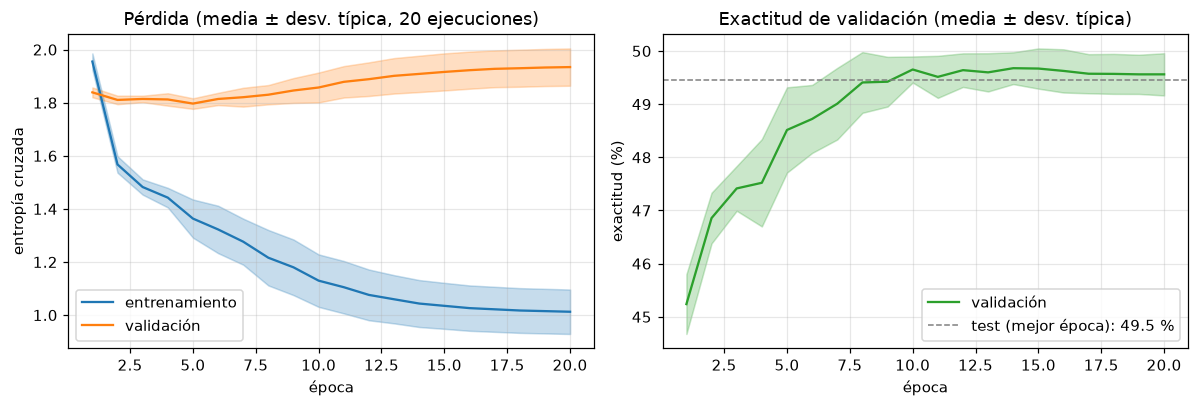

mejor época por ejecución: {4: 1, 5: 10, 6: 2, 7: 4, 8: 1, 10: 2}


In [23]:
curvas = {k: np.array([e['hist'][k] for e in ejecuciones]) for k in ('train_loss', 'val_loss', 'val_acc')}
ep = np.arange(1, EPOCAS_FINAL + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, etiqueta, color in [('train_loss', 'entrenamiento', 'tab:blue'), ('val_loss', 'validación', 'tab:orange')]:
    mu, sd = curvas[k].mean(0), curvas[k].std(0)
    ax[0].plot(ep, mu, color=color, label=etiqueta); ax[0].fill_between(ep, mu - sd, mu + sd, color=color, alpha=0.25)
ax[0].set_xlabel('época'); ax[0].set_ylabel('entropía cruzada'); ax[0].set_title('Pérdida (media ± desv. típica, 20 ejecuciones)')
ax[0].legend()
mu, sd = 100 * curvas['val_acc'].mean(0), 100 * curvas['val_acc'].std(0)
ax[1].plot(ep, mu, color='tab:green', label='validación'); ax[1].fill_between(ep, mu - sd, mu + sd, color='tab:green', alpha=0.25)
ax[1].axhline(100 * acc_media, color='gray', ls='--', lw=1, label=f'test (mejor época): {100 * acc_media:.1f} %')
ax[1].set_xlabel('época'); ax[1].set_ylabel('exactitud (%)'); ax[1].set_title('Exactitud de validación (media ± desv. típica)')
ax[1].legend()
plt.tight_layout(); plt.show()
print('mejor época por ejecución:', tabla_20['mejor_época'].value_counts().sort_index().to_dict())

**Resultado final: 49,46 % ± 0,24 % de exactitud en test** (20 ejecuciones; mínimo 49,0 %, máximo 50,0 %).

* **La pérdida de entrenamiento baja de forma continua** (de 1,96 a 1,01) gracias a la reducción de la tasa. Sin ella, con tasa 0,01 constante, la pérdida de entrenamiento volvía a subir a partir de la época 6: era inestabilidad, no aprendizaje.
* **La pérdida de validación es mínima hacia la época 5** y después sube, aunque la de entrenamiento siga bajando. Es **sobreajuste**: con ≈ 53 000 caracteres de entrenamiento y ≈ 80 000 parámetros, la red empieza a memorizar enseguida. La mejor época, según la pérdida de validación, está entre la 4 y la 10 en todas las ejecuciones.
* **La exactitud de validación sigue subiendo un poco** (≈ 49,7 % hacia la época 10) mientras la pérdida sube. La red acierta el carácter más probable igual o mejor, pero se vuelve **demasiado segura** en sus errores, y eso es lo que penaliza la entropía cruzada. Como se elige el modelo por pérdida, la exactitud en test (49,5 %) queda un poco por debajo de ese máximo.
* **El resultado es muy estable entre semillas** (± 0,24 puntos), y validación (49,3 %) y test (49,5 %) coinciden. Elegir los hiperparámetros con la validación no la ha sobreajustado.

# 4. Perplejidad en test

La **perplejidad** es la exponencial de la entropía cruzada media (teoría del Lab 1):

$$\mathrm{PP} = \exp\left(-\frac{1}{N}\sum_{i=1}^{N}\log p(c_i\mid \text{20 caracteres anteriores})\right).$$

Se interpreta como el **número efectivo de caracteres** entre los que duda el modelo en cada predicción: 1 sería certeza total y 28 (el tamaño del vocabulario) sería no saber nada (distribución uniforme).

In [24]:
pp_media, pp_std = tabla_20['test_pp'].mean(), tabla_20['test_pp'].std()
print(f'Perplejidad en test: {pp_media:.3f} ± {pp_std:.3f}  (20 ejecuciones)')
print(f'Referencias: uniforme = {V}')

# Referencias con modelos de n-gramas de caracteres (contar en el 30 % de entrenamiento, suavizado de Laplace)
def ngramas_pp(n, k=1.0):
    tr, te = texto[:n_tr], texto[n_va:]
    contexto, conjunto = collections.Counter(), collections.Counter()
    for i in range(n - 1, len(tr)):
        conjunto[tr[i - n + 1:i + 1]] += 1; contexto[tr[i - n + 1:i]] += 1
    logp, aciertos, N = 0.0, 0, 0
    for i in range(20, len(te)):                         # mismas posiciones evaluables que la RNN
        ctx = te[i - n + 1:i]
        logp += math.log((conjunto[ctx + te[i]] + k) / (contexto[ctx] + k * V))
        mejor = max(vocab, key=lambda c: conjunto[ctx + c])
        aciertos += mejor == te[i]; N += 1
    return math.exp(-logp / N), aciertos / N

tabla_ng = pd.DataFrame([dict(zip(['perplejidad', 'exactitud'], ngramas_pp(k))) for k in range(1, 7)],
                        index=[f'{k}-grama (contexto {k - 1})' for k in range(1, 7)])
tabla_ng.loc['RNN vanilla (contexto 20), 20 ejecuciones'] = [pp_media, acc_media]
display(tabla_ng)

Perplejidad en test: 5.964 ± 0.098  (20 ejecuciones)
Referencias: uniforme = 28


,perplejidad,exactitud
1-grama (contexto 0),17.8035,0.1829
2-grama (contexto 1),10.2648,0.2918
3-grama (contexto 2),7.2812,0.3952
4-grama (contexto 3),7.3742,0.4806
5-grama (contexto 4),9.8132,0.4976
6-grama (contexto 5),13.3762,0.4565
"RNN vanilla (contexto 20), 20 ejecuciones",5.9645,0.4946


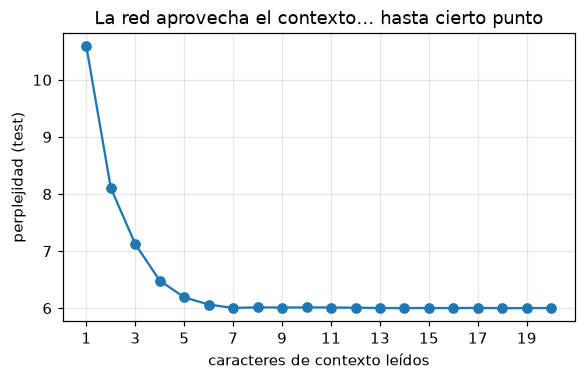

perplejidad con 1, 2, 3, 5, 10 y 20 caracteres de contexto: [10.59  8.11  7.12  6.19  6.01  6.  ]


In [25]:
# Perplejidad según cuántos caracteres de contexto ha leído la red (posición dentro de la ventana)
modelo_ref.eval()
with torch.no_grad():
    suma = torch.zeros(20)
    for i in range(0, len(Xte), 8192):
        logits = modelo_ref(Xte[i:i + 8192])
        suma += F.cross_entropy(logits.transpose(1, 2), Yte[i:i + 8192], reduction='none').sum(0)
pp_pos = torch.exp(suma / len(Xte)).numpy()
plt.figure(figsize=(6, 3.4))
plt.plot(range(1, 21), pp_pos, marker='o')
plt.xlabel('caracteres de contexto leídos'); plt.ylabel('perplejidad (test)')
plt.title('La red aprovecha el contexto… hasta cierto punto'); plt.xticks(range(1, 21, 2)); plt.show()
print('perplejidad con 1, 2, 3, 5, 10 y 20 caracteres de contexto:', np.round(pp_pos[[0, 1, 2, 4, 9, 19]], 2))

**Perplejidad en test: 5,96 ± 0,10.** En cada predicción, la red duda en promedio como si eligiera entre **unos 6 caracteres** igual de probables, frente a 28 si no supiera nada y 17,8 si solo conociera la frecuencia de cada letra.

**Comparación con los n-gramas** (los mismos del Lab 1, entrenados por conteo con el mismo 30 % del texto):

* En **perplejidad**, la RNN es la mejor con diferencia: 5,96 frente a 7,28 del mejor n-grama (trigrama). Los n-gramas largos se disparan (13,4 con 6-gramas): casi todos los contextos largos son raros (la cola de Zipf) y el suavizado de Laplace reparte mal la probabilidad.
* En **exactitud**, la RNN (49,5 %) **empata prácticamente con el mejor n-grama**, un 5-grama (49,8 %). Con tan poco texto de entrenamiento, «contar y elegir lo más frecuente» es una regla muy buena para el carácter más probable, aunque las probabilidades que asigna sean malas.

Así, la RNN da **probabilidades mucho mejor calibradas**, que es lo que se necesita para generar texto o como modelo de lenguaje.

**La memoria efectiva de la RNN vanilla es corta.** La perplejidad es 10,6 con 1 carácter de contexto, 7,1 con 3, 6,2 con 5 y 6,0 a partir de unos 7 caracteres, donde deja de bajar. La red aprovecha los últimos 5–7 caracteres, pero lo anterior apenas cambia sus predicciones. Es el **desvanecimiento del gradiente** de la teoría en acción, y la razón de que existan las LSTM.

## 4.1. Cómo predice la red el siguiente carácter

Para un contexto de 20 caracteres, la red da una distribución de probabilidad (softmax de los logits) sobre los 28 símbolos; la predicción es el de mayor probabilidad. Encadenando predicciones (se añade el carácter predicho y se desplaza la ventana) se puede **generar texto**.

In [26]:
def top_k(modelo, contexto, k=5):
    x = torch.tensor([[c2i[c] for c in preprocesar(contexto)[-20:]]])
    with torch.no_grad():
        p = F.softmax(modelo(x)[0, -1], dim=-1)
    v, i = p.topk(k)
    return ', '.join(f'{i2c[int(j)]!r} {float(q):.2f}' for q, j in zip(v, i))

for ctx in ['the time traveller w', 'it was very differen', 'i saw the morlocks a', 'there was a moment o']:
    print(f'{ctx!r:26} -> {top_k(modelo_ref, ctx)}')

def generar(modelo, semilla, n=160, temperatura=None, gen=None):
    s = preprocesar(semilla)
    for _ in range(n):
        x = torch.tensor([[c2i[c] for c in s[-20:]]])
        with torch.no_grad():
            logits = modelo(x)[0, -1]
        if temperatura is None:
            j = int(logits.argmax())
        else:
            j = int(torch.multinomial(F.softmax(logits / temperatura, dim=-1), 1, generator=gen))
        s += i2c[j]
    return s

print('\nvoraz (siempre el más probable):\n ', generar(modelo_ref, 'the time traveller w'))
print('muestreo (temperatura 0,7):\n ', generar(modelo_ref, 'the time traveller w', temperatura=0.7,
                                               gen=torch.Generator().manual_seed(0)))

'the time traveller w'     -> 'a' 0.77, 'i' 0.10, 'o' 0.04, 'h' 0.04, 'e' 0.04
'it was very differen'     -> 't' 0.52, 'c' 0.38, 'd' 0.06, 'g' 0.02, 'v' 0.01
'i saw the morlocks a'     -> 'l' 0.30, ' ' 0.28, 'n' 0.19, 'b' 0.08, 'g' 0.03
'there was a moment o'     -> 'n' 0.66, 'f' 0.19, 'u' 0.09, 'l' 0.02, 'b' 0.02

voraz (siempre el más probable):
  the time traveller was a minute of the time traveller_ _it machine had a brown the time traveller_ _it machine had a brown the time traveller_ _it machine had a brown the time trav
muestreo (temperatura 0,7):
  the time traveller walked and with of the whim it was always fool are along the intermnited his chair and dashed it_s sound round soot man smoking the line me_ with a lot the hout 


Las predicciones son razonables:

* Tras «the time traveller w», la red da un 77 % a «a» (*was*).
* Tras «it was very differen», duda entre «t» (*different*, 52 %) y «c» (*difference*, 38 %): las dos continuaciones son correctas.
* Cuando el contexto es ambiguo («i saw the morlocks a…»), reparte la probabilidad.

El texto generado reproduce lo que describe la teoría para las RNN vanilla de caracteres:

* **Sintaxis local correcta**: palabras reales (*walked*, *always*, *chair*, *dashed*, *sound*, *round*, *smoking*) y espacios bien puestos.
* **Sin coherencia global**: no hay frases con sentido.
* **La generación voraz entra en un bucle** («the time traveller_ _it machine had a brown the time traveller_…»), porque siempre elige lo mismo ante el mismo contexto. «the time traveller» es la secuencia más repetida del libro.
* **El muestreo con temperatura 0,7** da más variedad, con algunas palabras inventadas («intermnited»).

# 5. Conclusiones

1. **El código original no entrenaba la red.** Tres fallos se combinaban:
   * hacía una sola actualización de pesos por época con todo el conjunto (10 en total);
   * usaba un `nn.Embedding` aprendido en lugar del one-hot exigido;
   * convertía cada `<unk>` en 5 caracteres, lo que inflaba la exactitud con un 16,5 % de aciertos regalados.

   Su 37,7 % (h = 64) equivale a un **20,6 %** con el texto corregido, apenas por encima de predecir siempre un espacio (18,3 %).
2. **Factores ordenados por su influencia** (rango de exactitud en validación entre la mejor y la peor opción de cada experimento):
   * **minilotes y pérdida en todas las posiciones** (≈ 26 puntos), la clave;
   * **tamaño de la capa oculta** (≈ 12 puntos, incluida la inestabilidad con 512);
   * **tasa de aprendizaje** y **activación con dropout** (≈ 3,4 puntos cada uno), donde quitar el dropout del 50 % es lo que cuenta;
   * **dropout con 256 neuronas** (2,2 puntos);
   * **reducir la tasa durante el entrenamiento** (1,0 punto);
   * **optimizador** (0,9), **recorte** (0,8) e **inicialización** (0,3), que influyen poco en este problema.
3. **Configuración final**: 256 neuronas, tanh, sin dropout, inicialización He, Adam con tasa 0,01 que se reduce a la mitad cuando la validación no mejora, recorte a 0,25, pérdida en las 20 posiciones, minilotes de 128 y parada temprana. En 20 ejecuciones logra **49,46 % ± 0,24 %** de exactitud y **perplejidad 5,96 ± 0,10** en test, frente al 20,6 % y la perplejidad 17,4 del original corregido.
4. **Gradientes.** Con tanh y 20 pasos no explotan (norma ≤ 3), pero con ReLU y una tasa alta divergen a NaN sin recorte. El recorte cuesta poco y evita ese fallo.
5. **Límites de la RNN vanilla.** Sobreajusta muy pronto con solo 53 000 caracteres de entrenamiento. Su memoria efectiva es de unos 5–7 caracteres: la perplejidad deja de bajar a partir de ahí. Empata en exactitud con un 5-grama, aunque con probabilidades mucho mejores. El texto que genera tiene palabras correctas pero no coherencia. Son las limitaciones que motivan las LSTM y GRU del siguiente lab.

In [27]:
def a_lista(df):
    return [{'opcion': str(i)} | {k: (None if pd.isna(v) else float(v)) for k, v in fila.items()}
            for i, fila in df.iterrows()]

resultados = {
    'original': {'hidden': hidden_sizes, 'acc': test_accuracies, 'n_unk': n_unk, 'longitud': total_length},
    'vocab': V, 'n': n, 'secuencias': [len(Xtr), len(Xva), len(Xte)],
    'experimentos': {k: a_lista(v) for k, v in {'lotes': exp1, 'lr': exp_lr, 'opt': exp_opt, 'act': exp_act,
                                                 'init': exp_init, 'h': exp_h, 'drop': exp_drop, 'clip': exp_clip,
                                                 'sched': exp_sched}.items()},
    'riesgo': riesgo,
    'config_final': {k: v for k, v in CONFIG_FINAL.items()},
    'comparacion': {k: {c: float(v) for c, v in fila.items()} for k, fila in comparacion.T.to_dict().items()},
    'final20': {'acc_media': acc_media, 'acc_std': acc_std, 'pp_media': pp_media, 'pp_std': pp_std,
                'curvas': {k: {'media': v.mean(0).tolist(), 'std': v.std(0).tolist()} for k, v in curvas.items()},
                'mejor_epoca': tabla_20['mejor_época'].tolist(), 'test_acc': tabla_20['test_acc'].tolist()},
    'ngramas': {i: [float(a), float(b)] for i, (a, b) in tabla_ng.iterrows()},
    'pp_posicion': pp_pos.tolist(),
}
with open(LAB_DIR / 'resultados_lab2_caracteres.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=1, default=float)
print('Resultados guardados en resultados_lab2_caracteres.json')

Resultados guardados en resultados_lab2_caracteres.json
